# QShield: Fast QSVM Validation

This notebook performs a lightweight QSVM experiment to validate the quantum pipeline before larger-scale experiments and hardware execution.

In [5]:
# Import libraries

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


In [7]:
# Import Qiskit components

from qiskit.circuit.library import ZZFeatureMap

from qiskit_machine_learning.kernels import (
    FidelityQuantumKernel
)

from qiskit_machine_learning.algorithms import (
    QSVC
)

In [9]:
# Load quantum dataset

df = pd.read_csv(
    "/Users/srinidhinunna/Desktop/HighQ/data/quantum_dataset.csv"
)

print(df.shape)

(4000, 14)


In [11]:
# Create a much smaller dataset for rapid testing

fraud = df[df["isFraud"] == 1].sample(
    200,
    random_state=42
)

nonfraud = df[df["isFraud"] == 0].sample(
    200,
    random_state=42
)

small_df = pd.concat(
    [fraud, nonfraud]
).sample(
    frac=1,
    random_state=42
)

print(small_df.shape)

print(small_df["isFraud"].value_counts())

(400, 14)
isFraud
0    200
1    200
Name: count, dtype: int64


In [13]:
# Select features

features = [
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "balance_error_orig",
    "balance_error_dest",
    "amount_ratio",
    "type"
]

X = small_df[features]

y = small_df["isFraud"]


In [15]:
# Standardize features

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [17]:
# Reduce to 4 dimensions

pca = PCA(
    n_components=4
)

X_pca = pca.fit_transform(X_scaled)

print(
    "Explained Variance:",
    round(
        pca.explained_variance_ratio_.sum(),
        4
    )
)

Explained Variance: 0.8928


In [19]:
# Train test split

X_train, X_test, y_train, y_test = train_test_split(
    X_pca,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(320, 4)
(80, 4)


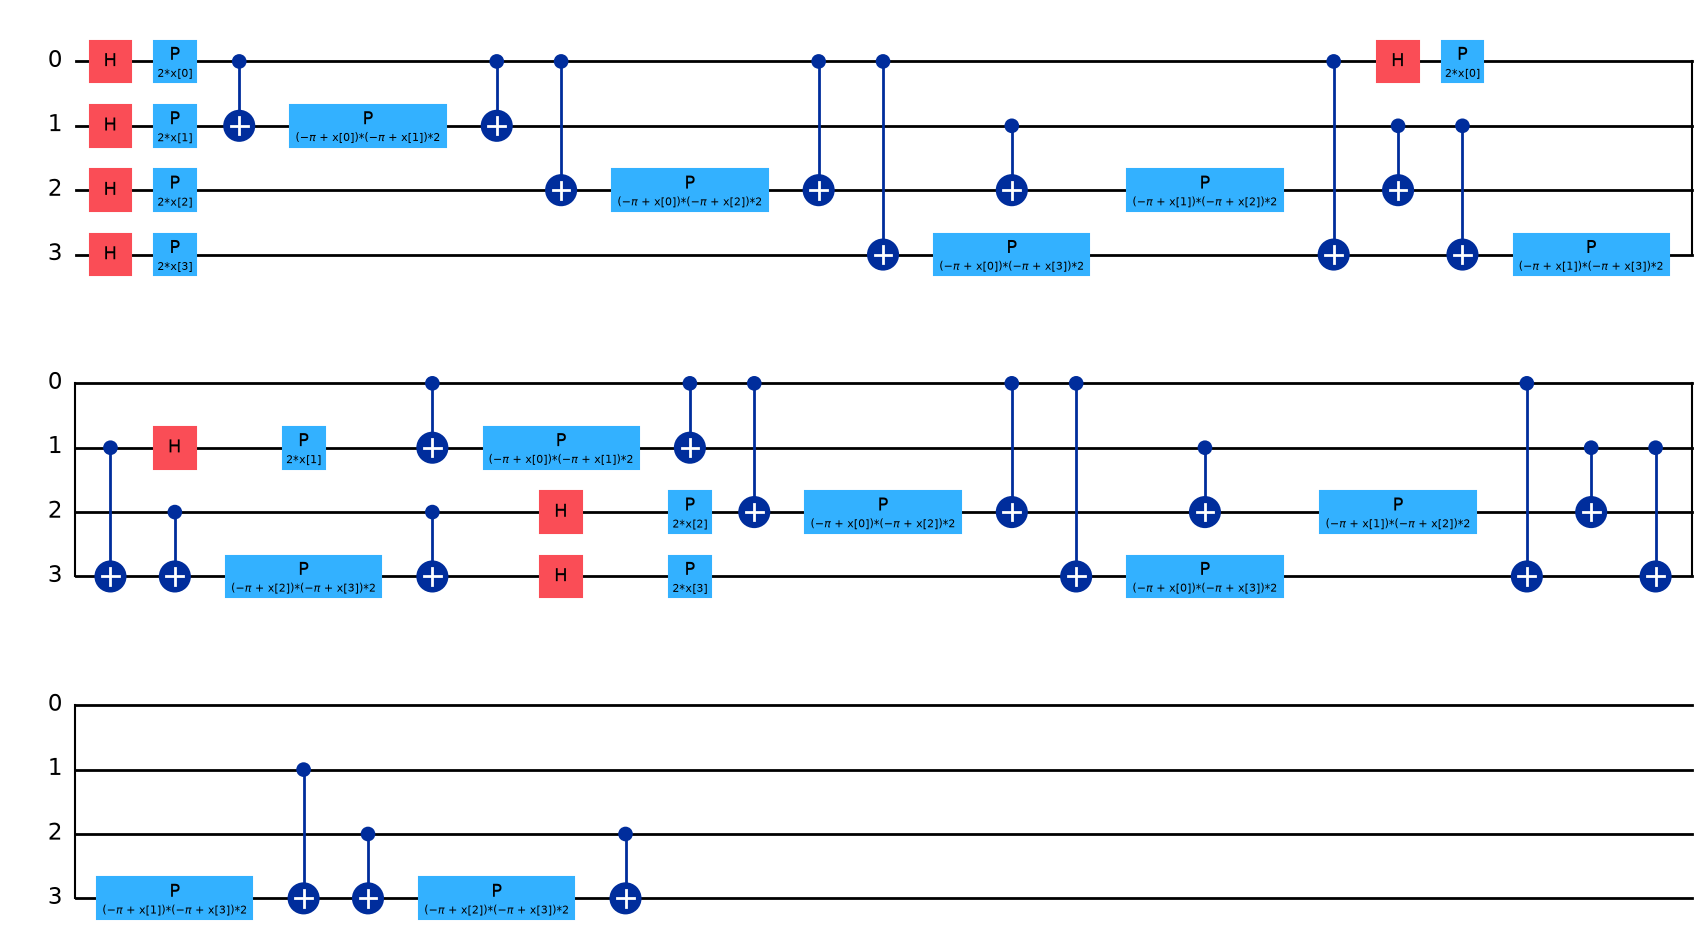

In [27]:
from qiskit.circuit.library import zz_feature_map

# Construct ZZFeatureMap circuit for quantum data embedding
feature_map = zz_feature_map(
    feature_dimension=4,
    reps=2
)

# Draw the circuit
feature_map.draw("mpl")

In [29]:
# Create quantum kernel

quantum_kernel = FidelityQuantumKernel(
    feature_map=feature_map
)

In [31]:
# Create QSVM

qsvc = QSVC(
    quantum_kernel=quantum_kernel
)

In [33]:
# Train

qsvc.fit(
    X_train,
    y_train
)

print("Training Complete")

Training Complete


In [34]:
# Predict

predictions = qsvc.predict(
    X_test
)

In [35]:
# Evaluate

accuracy = accuracy_score(
    y_test,
    predictions
)

precision = precision_score(
    y_test,
    predictions
)

recall = recall_score(
    y_test,
    predictions
)

f1 = f1_score(
    y_test,
    predictions
)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.8
Precision: 0.7608695652173914
Recall   : 0.875
F1 Score : 0.813953488372093
